# Tugas Besar 2 IF3170 Inteligensi Artifisial

## Group 20

- Faiq Azzam Nafidz (13524003)
- Mikhael Benrael Tampubolon (13524009)
- Muhammad Nafis Habibi (13524018)
- Syaqina Octavia Rizha (13524088)
- Muhammad Rafi Akbar (13524128)

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)

---

# 1. Introduction <a name="1"></a>

---

## Overview & Aim

Notebook ini membangun pipeline klasifikasi pembatalan reservasi hotel (`is_canceled`) secara modular (satu fungsi per proses), bebas *data leakage*, dan **sepenuhnya menggunakan algoritma klasik implementasi *from-scratch* tanpa ensemble**:
**KNN, Decision Tree Learning (DTL), Logistic Regression, SVM, dan Naive Bayes**.

- **Dataset**: 27.373 baris latih (`train.csv`) dan 6.844 baris uji (`test.csv`).
- **Metrik Evaluasi**: **Macro F1-Score** (`f1_score(..., average='macro')`).
- **Pendekatan**: Feature engineering domain & temporal, `ColumnTransformer` + `Pipeline`, tuning hyperparameter menggunakan **Grid Search**, perbandingan dengan `scikit-learn`, serta prediksi akhir menggunakan model *from-scratch* terbaik.

---

# 2. Initialization <a name="2"></a>

---

## Environment Setup & Imports

In [1]:
# Uncomment jika dijalankan di environment baru (Colab / Deepnote)
# %pip install -q numpy pandas scikit-learn matplotlib seaborn
%pip install graphviz


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
import json
import pickle
import random
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)
from sklearn.model_selection import ParameterGrid, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

ROOT_DIR = Path.cwd() if (Path.cwd() / 'input').exists() else Path.cwd().parent
SRC_DIR = ROOT_DIR / 'src' if (ROOT_DIR / 'src' / 'scratch_model').exists() else ROOT_DIR
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from scratch_model.knn import KNN as sm_KNN
from scratch_model.dtl import DecisionTreeClassifier as sm_DecisionTreeClassifier
from scratch_model.logistic_regression import LogisticRegression as sm_LogisticRegression
from scratch_model.svm import SVM as sm_SVM
from scratch_model.naive_bayes import NaiveBayes as sm_NaiveBayes

## Settings & Reproducibility

In [3]:
class Settings:
    SEED            = 42
    PROJECT_ROOT    = ROOT_DIR
    DATA_DIR        = ROOT_DIR / 'input'
    OUTPUT_DIR      = ROOT_DIR / 'output'
    MODEL_DIR       = ROOT_DIR / 'output' / 'saved_models'
    TARGET_COLUMN   = 'is_canceled'
    ID_COLUMN       = 'id'
    RUN_GRID_SEARCH = True  # Set False jika ingin langsung load model/parameter tersimpan

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.MODEL_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed: int) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

set_seed(CFG.SEED)

## Data Loading

In [4]:
def load_data(data_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    train_df = pd.read_csv(data_dir / 'train.csv', dtype={CFG.ID_COLUMN: str})
    test_df  = pd.read_csv(data_dir / 'test.csv', dtype={CFG.ID_COLUMN: str})
    print(f'Train: {train_df.shape} | Test: {test_df.shape}')
    print('Target proportion:', train_df[CFG.TARGET_COLUMN].value_counts(normalize=True).round(4).to_dict())
    return train_df, test_df

train_df, test_df = load_data(CFG.DATA_DIR)
display(train_df.head())

Train: (27373, 19) | Test: (6844, 18)
Target proportion: {0: 0.6723, 1: 0.3277}


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


---

# 3. Data Understanding <a name="3"></a>

---

## Visualisasi & Kualitas Data

- **Fitur Numerik**: scatter plot terhadap `is_canceled`.
- **Fitur Kategorikal**: histogram (stacked count) per kelas target.

nightly_rate_idr == 0 -> count=413, cancel_rate=0.0073


,Column,Train NA (%),Test NA (%),Cancel Rate (NA)
0,num_adults,2.96,2.63,0.3350
1,num_children,11.09,10.91,0.3282
2,weekend_nights,0.00,0.00,NaN
3,weekday_nights,0.00,0.00,NaN
4,meal_package,6.43,6.46,0.3193
5,needs_parking,3.95,3.61,0.3124
6,room_category,3.66,3.54,0.3483
7,days_before_arrival,4.10,4.24,0.3117
8,arrival_year,0.00,0.00,NaN
9,arrival_month,0.00,0.00,NaN


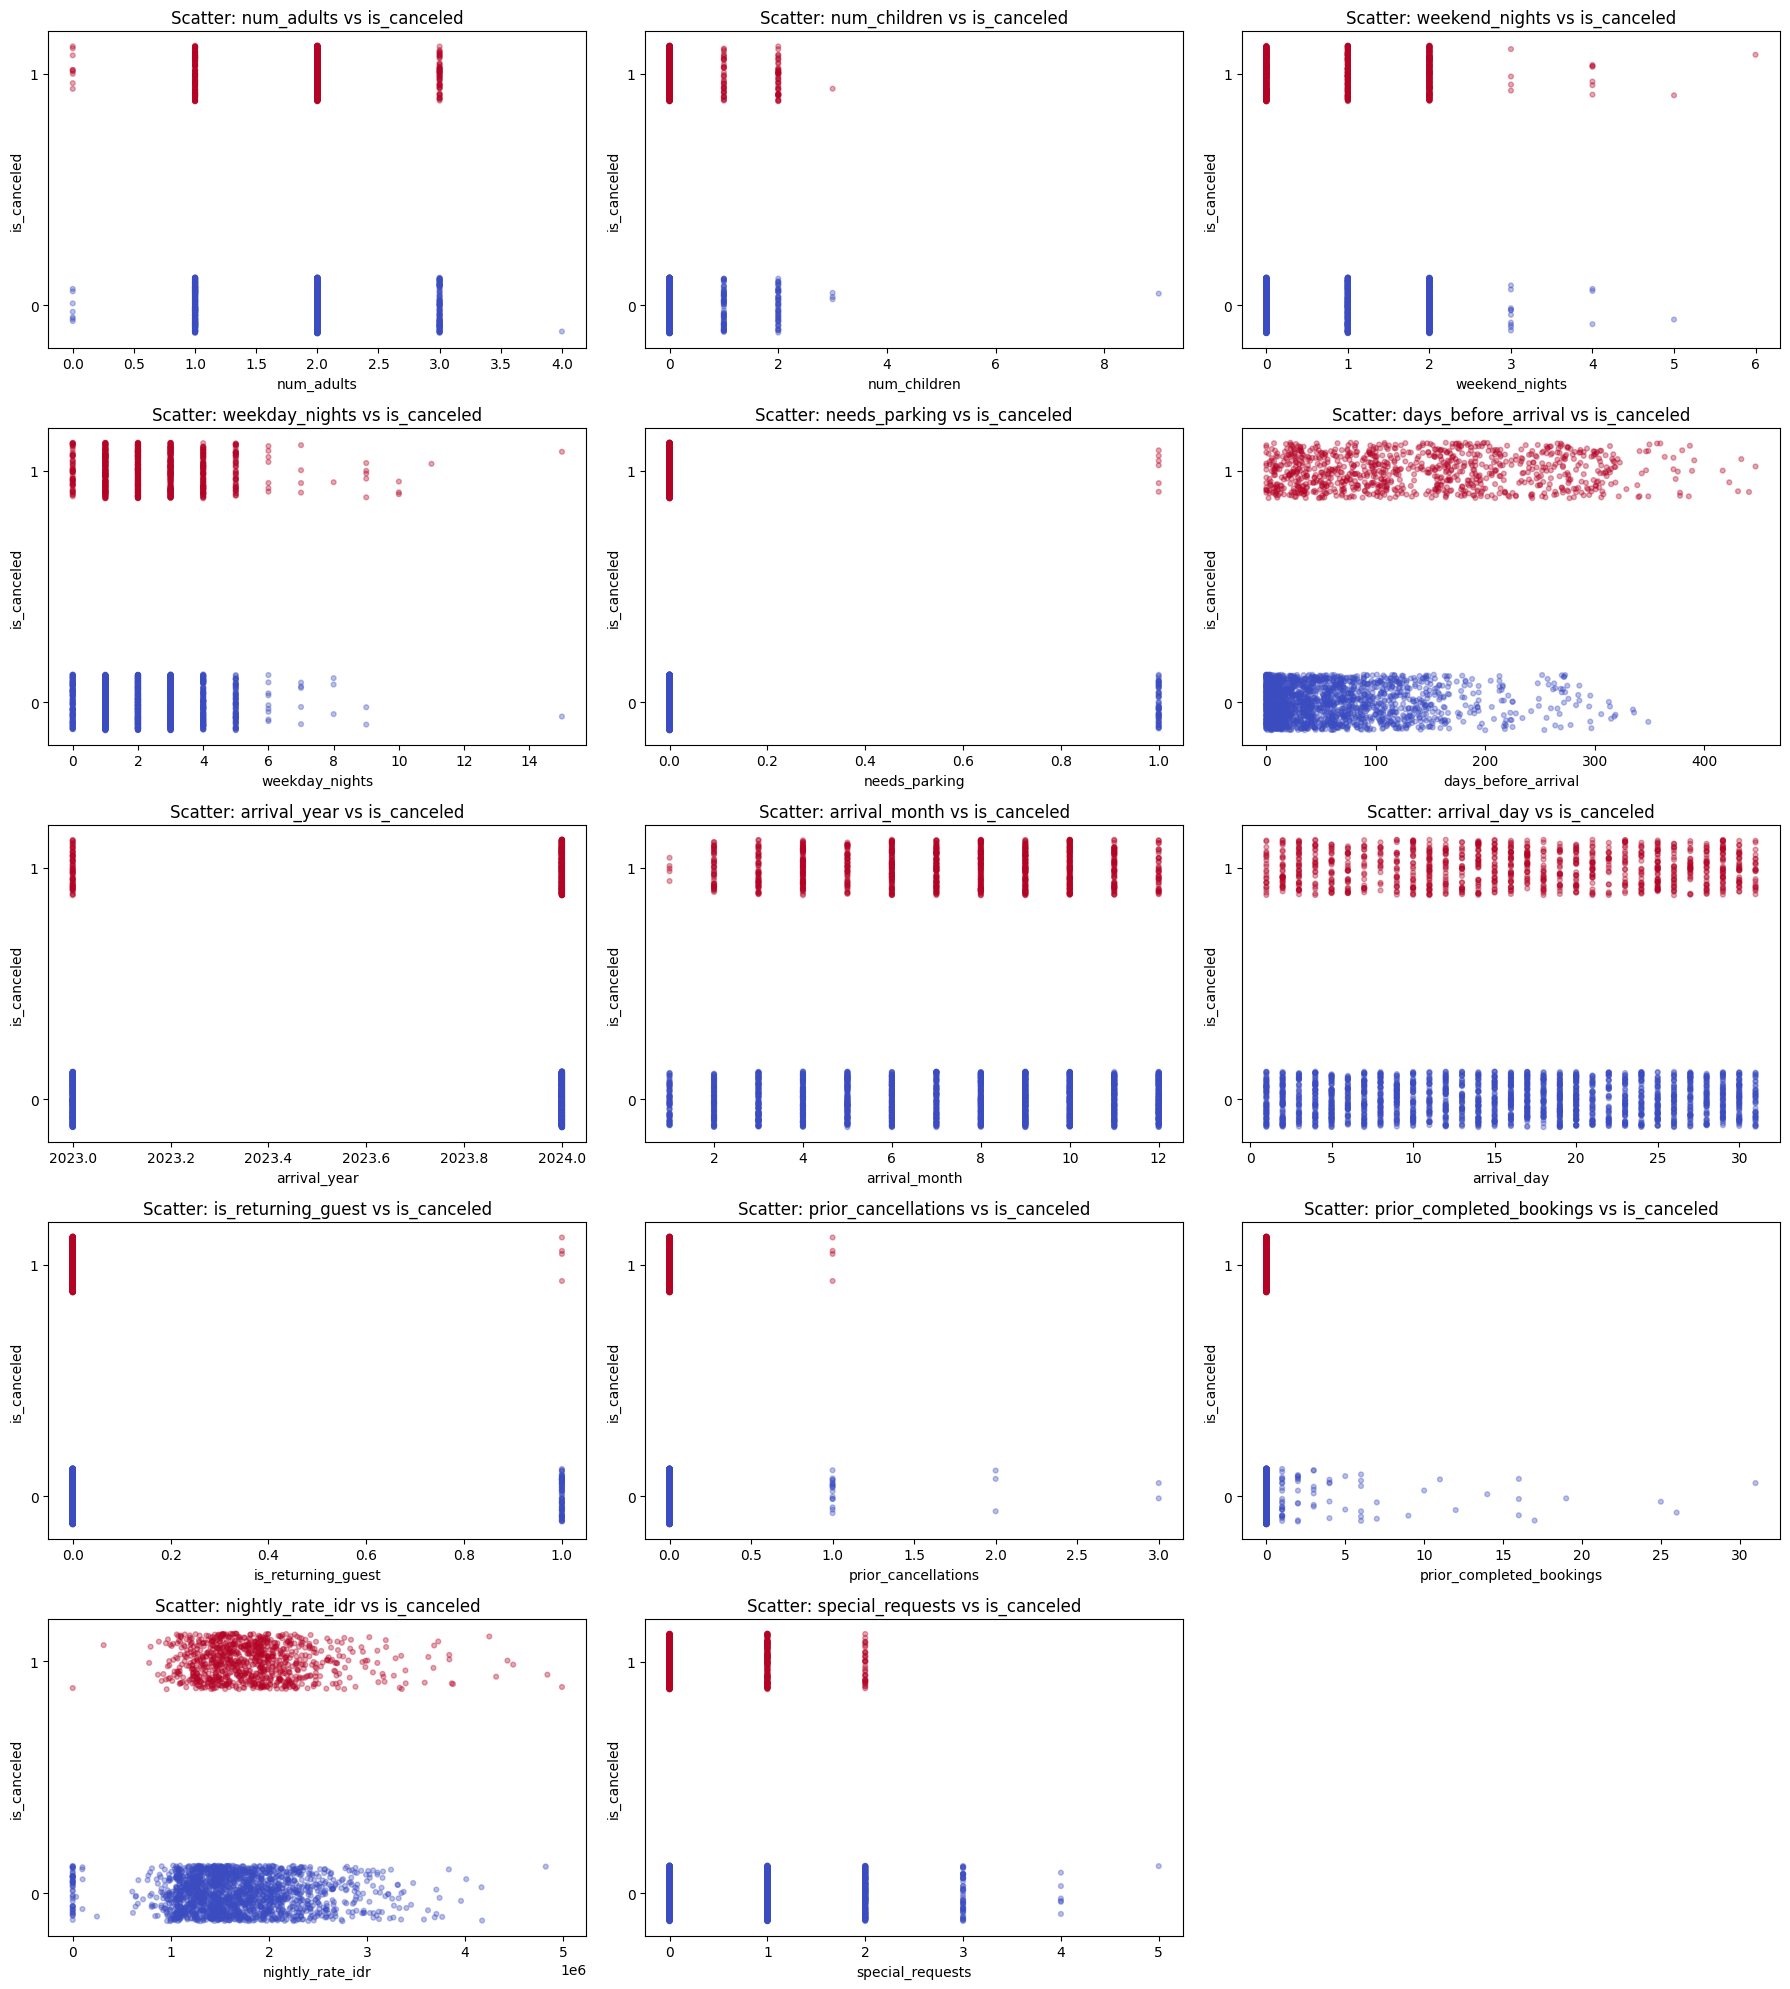

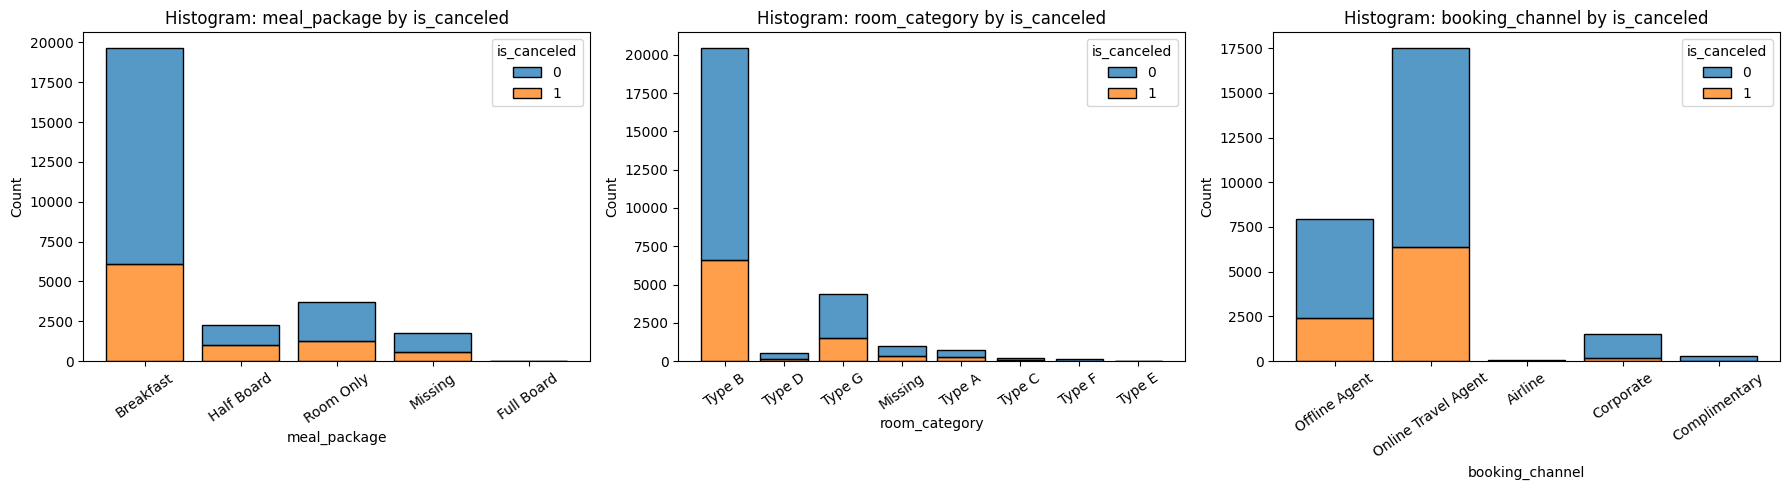

In [5]:
def plot_numeric(df: pd.DataFrame, target_col: str = CFG.TARGET_COLUMN, sample_n: int = 3000) -> None:
    num_cols = [c for c in df.select_dtypes(include=np.number).columns if c != target_col]
    sample_df = df.sample(min(sample_n, len(df)), random_state=CFG.SEED)
    n_cols = 3
    n_rows = int(np.ceil(len(num_cols) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
    axes = np.array(axes).flatten()

    jitter = np.random.default_rng(CFG.SEED).uniform(-0.12, 0.12, size=len(sample_df))
    for i, col in enumerate(num_cols):
        axes[i].scatter(
            sample_df[col],
            sample_df[target_col] + jitter,
            c=sample_df[target_col],
            cmap='coolwarm',
            alpha=0.35,
            s=12,
        )
        axes[i].set_title(f'Scatter: {col} vs {target_col}')
        axes[i].set_xlabel(col)
        axes[i].set_yticks([0, 1])
        axes[i].set_ylabel(target_col)

    for i in range(len(num_cols), len(axes)):
        axes[i].set_visible(False)
    plt.tight_layout()
    plt.show()

def plot_categorical(df: pd.DataFrame, target_col: str = CFG.TARGET_COLUMN) -> None:
    cat_cols = [
        c for c in df.select_dtypes(include=['object', 'category']).columns
        if c not in (CFG.ID_COLUMN, target_col)
    ]
    fig, axes = plt.subplots(1, len(cat_cols), figsize=(6 * len(cat_cols), 5))
    if len(cat_cols) == 1:
        axes = [axes]

    for ax, col in zip(axes, cat_cols):
        plot_df = df[[col, target_col]].copy()
        plot_df[col] = plot_df[col].fillna('Missing')
        sns.histplot(data=plot_df, x=col, hue=target_col, multiple='stack', shrink=0.8, ax=ax)
        ax.set_title(f'Histogram: {col} by {target_col}')
        ax.tick_params(axis='x', rotation=35)
    plt.tight_layout()
    plt.show()

def check_quality(train_df: pd.DataFrame, test_df: pd.DataFrame) -> pd.DataFrame:
    # Cek persentase missing value
    rows = []
    for col in train_df.columns.drop([CFG.ID_COLUMN, CFG.TARGET_COLUMN]):
        na_tr = train_df[col].isna().mean() * 100
        na_te = test_df[col].isna().mean() * 100
        cr_na = train_df.loc[train_df[col].isna(), CFG.TARGET_COLUMN].mean() if na_tr > 0 else np.nan
        rows.append({
            'Column': col,
            'Train NA (%)': round(na_tr, 2),
            'Test NA (%)': round(na_te, 2),
            'Cancel Rate (NA)': round(cr_na, 4) if pd.notna(cr_na) else np.nan,
        })
    zero_rate = train_df[train_df['nightly_rate_idr'] == 0]
    print(f'nightly_rate_idr == 0 -> count={len(zero_rate)}, cancel_rate={zero_rate[CFG.TARGET_COLUMN].mean():.4f}')
    return pd.DataFrame(rows)

display(check_quality(train_df, test_df))
plot_numeric(train_df)
plot_categorical(train_df)

---

# 4. Training and Validation Split <a name="4"></a>

---

In [6]:
def split_data(
    train_df: pd.DataFrame,
    target_col: str = CFG.TARGET_COLUMN,
    test_size: float = 0.2,
    seed: int = CFG.SEED,
):
    """Pisahkan fitur & target, lalu lakukan stratified train/val split."""
    X = train_df.drop(columns=[CFG.ID_COLUMN, target_col]).copy()
    y = train_df[target_col].astype(int).copy()
    X_tr, X_va, y_tr, y_va = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=seed
    )
    print(f'Split -> X_train: {X_tr.shape}, X_val: {X_va.shape}')
    return X, y, X_tr, X_va, y_tr, y_va

X_full_raw, y_full, X_train_raw, X_val_raw, y_train, y_val = split_data(train_df)
X_test_raw = test_df.drop(columns=[CFG.ID_COLUMN]).copy()

Split -> X_train: (21898, 17), X_val: (5475, 17)


---

# 5. Data Preparation <a name="5"></a>

---

## Data Cleaning & Feature Engineering

Keputusan berbasis EDA:
1. Pertahankan `arrival_day` untuk membentuk fitur temporal (`arrival_days_since_start`, `arrival_dow`, `booking_days_since_start`).
2. Pertahankan `nightly_rate_idr == 0` (cancel rate 0.73%) dan buat flag `is_zero_rate`.
3. Hindari IQR clipping global karena 7 kolom numerik memiliki `IQR = 0`.
4. Tambahkan `special_requests_isna` (MNAR) dan interaksi `ota_no_special_req`.

In [7]:
def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    cols = [
        'nightly_rate_idr', 'days_before_arrival', 'num_adults', 'num_children',
        'weekend_nights', 'weekday_nights', 'special_requests',
        'prior_cancellations', 'prior_completed_bookings',
    ]
    for col in cols:
        if col in df.columns:
            df.loc[df[col] < 0, col] = np.nan
    return df

def add_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    df['special_requests_isna'] = df['special_requests'].isna().astype(int)
    df['total_nights'] = df['weekend_nights'] + df['weekday_nights']
    df['is_zero_nights'] = (df['total_nights'] == 0).astype(int)
    df['total_guests'] = df['num_adults'].fillna(2.0) + df['num_children'].fillna(0.0)
    df['is_zero_rate'] = (df['nightly_rate_idr'] == 0).astype(int)
    df['total_cost_est'] = df['nightly_rate_idr'] * np.maximum(df['total_nights'], 1)
    df['prior_cancel_ratio'] = df['prior_cancellations'] / (
        df['prior_cancellations'] + df['prior_completed_bookings'] + 1.0
    )

    df['log_days_before'] = np.log1p(df['days_before_arrival'].clip(lower=0))
    df['log_nightly_rate'] = np.log1p(df['nightly_rate_idr'].clip(lower=0))

    sr_filled = df['special_requests'].fillna(0.0)
    df['ota_no_special_req'] = (
        (df['booking_channel'] == 'Online Travel Agent') & (sr_filled == 0)
    ).astype(int)

    arrival_dt = pd.to_datetime(
        dict(year=df['arrival_year'], month=df['arrival_month'], day=df['arrival_day'])
    )
    ref_date = pd.Timestamp('2023-07-01')
    df['arrival_days_since_start'] = (arrival_dt - ref_date).dt.days
    df['arrival_dow'] = arrival_dt.dt.day_of_week
    df['month_sin'] = np.sin(2 * np.pi * df['arrival_month'] / 12.0)
    df['month_cos'] = np.cos(2 * np.pi * df['arrival_month'] / 12.0)

    booking_dt = arrival_dt - pd.to_timedelta(df['days_before_arrival'].fillna(58.0), unit='D')
    df['booking_days_since_start'] = (booking_dt - ref_date).dt.days
    return df

X_full  = add_features(clean_data(X_full_raw))
X_train = add_features(clean_data(X_train_raw))
X_val   = add_features(clean_data(X_val_raw))
X_test  = add_features(clean_data(X_test_raw))
print(f'Feature shape -> X_train: {X_train.shape}, X_val: {X_val.shape}, X_test: {X_test.shape}')

Feature shape -> X_train: (21898, 32), X_val: (5475, 32), X_test: (6844, 32)


---

# 6. Preparation Pipeline <a name="6"></a>

---

In [8]:
def make_preprocessor(X_sample: pd.DataFrame) -> ColumnTransformer:
    """Imputasi, StandardScaler, OneHotEncoder"""
    cat_cols = ['meal_package', 'room_category', 'booking_channel']
    num_cols = [c for c in X_sample.columns if c not in cat_cols]

    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    return ColumnTransformer([
        ('num', num_pipe, num_cols),
        ('cat', cat_pipe, cat_cols),
    ])

def prepare_data(X_tr: pd.DataFrame, X_va: pd.DataFrame):
    prep = make_preprocessor(X_tr)
    X_tr_np = prep.fit_transform(X_tr)
    X_va_np = prep.transform(X_va)
    cols = list(prep.get_feature_names_out())
    return prep, pd.DataFrame(X_tr_np, columns=cols), pd.DataFrame(X_va_np, columns=cols)

preprocessor, X_train_prep, X_val_prep = prepare_data(X_train, X_val)
print(f'Prepared -> X_train_prep: {X_train_prep.shape}, X_val_prep: {X_val_prep.shape}')

Prepared -> X_train_prep: (21898, 47), X_val_prep: (5475, 47)


---

# 7. Modeling and Validation (From-Scratch, Tanpa Ensemble) <a name="7"></a>

---

## 7.1 Hyperparameter Tuning (Grid Search)

Jika `CFG.RUN_GRID_SEARCH = True`, fungsi `grid_search()` mencari parameter terbaik untuk kelima model *from-scratch* dan menyimpannya ke `output/saved_models/best_params.json`. Jika `False`, notebook akan memuat parameter dari file tersimpan tersebut (atau memakai nilai default standar jika file belum ada).

In [9]:
PARAM_GRIDS = {
    'knn': {
        'k_neighbors': [5, 9, 15, 19, 25],
        'weights': ['uniform', 'distance'],
        'metric': ['euclidean', 'manhattan'],
    },
    'dtl': {
        'criterion': ['gini', 'entropy', 'gain_ratio'],
        'max_depth': [8, 12, 16, 20, 24],
        'min_samples_leaf': [5, 7, 10, 15],
        'min_samples_split': [10, 20, 40],
        'ccp_alpha': [0.0, 0.001],
    },
    'lr': {
        'penalty': ['l2', 'l1'],
        'C': [0.1, 0.5, 1.0, 2.5, 5.0, 10.0],
        'learning_rate': [0.05, 0.1, 0.2, 0.5],
        'max_iter': [1000],
    },
    'svm': {
        'C': [0.5, 1.0, 2.0, 5.0, 10.0],
        'kernel': ['linear', 'rbf'],
        'max_iter': [300],
        'learning_rate': [1e-2],
    },
    'nb': {
        'var_smoothing': [1e-6, 1e-3, 1e-1, 0.5, 1.0, 3.0, 5.0],
    },
}

DEFAULT_PARAMS = {
    'knn': {'k_neighbors': 15, 'weights': 'distance', 'metric': 'manhattan'},
    'dtl': {'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 10, 'min_samples_split': 20, 'ccp_alpha': 0.0},
    'lr':  {'penalty': 'l2', 'C': 1.0, 'max_iter': 1000, 'learning_rate': 0.1},
    'svm': {'C': 1.0, 'kernel': 'rbf', 'max_iter': 300, 'learning_rate': 1e-2},
    'nb':  {'var_smoothing': 1e-3},
}

def grid_search(
    X_tr_df: pd.DataFrame,
    y_tr: pd.Series,
    X_va_df: pd.DataFrame,
    y_va: pd.Series,
    param_grids: dict = PARAM_GRIDS,
    knn_val_n: int = 800,
    svm_train_n: int = 1200,
) -> dict:
    """Jalankan Grid Search pada 5 model from-scratch berdasarkan Macro F1 validasi."""
    X_tr_np, y_tr_np = X_tr_df.to_numpy(), y_tr.to_numpy()
    X_va_np, y_va_np = X_va_df.to_numpy(), y_va.to_numpy()
    found = {}

    # 1. KNN
    v_idx = np.random.default_rng(CFG.SEED).choice(len(X_va_np), size=min(knn_val_n, len(X_va_np)), replace=False)
    best_f1, best_p = -1.0, None
    for p in ParameterGrid(param_grids['knn']):
        m = sm_KNN(**p).fit(X_tr_np, y_tr_np)
        score = f1_score(y_va_np[v_idx], m.predict(X_va_np[v_idx]), average='macro')
        if score > best_f1:
            best_f1, best_p = score, p
    found['knn'] = best_p
    print(f'GridSearch KNN : {best_f1:.5f} | {best_p}')

    # 2. Decision Tree
    best_f1, best_p = -1.0, None
    for p in ParameterGrid(param_grids['dtl']):
        if p['min_samples_split'] < 2 * p['min_samples_leaf']:
            continue
        m = sm_DecisionTreeClassifier(**p, random_state=CFG.SEED).fit(X_tr_np, y_tr_np)
        score = f1_score(y_va_np, m.predict(X_va_np), average='macro')
        if score > best_f1:
            best_f1, best_p = score, p
    found['dtl'] = best_p
    print(f'GridSearch DTL : {best_f1:.5f} | {best_p}')

    # 3. Logistic Regression
    best_f1, best_p = -1.0, None
    for p in ParameterGrid(param_grids['lr']):
        m = sm_LogisticRegression(**p, random_state=CFG.SEED).fit(X_tr_np, y_tr_np)
        score = f1_score(y_va_np, m.predict(X_va_np), average='macro')
        if score > best_f1:
            best_f1, best_p = score, p
    found['lr'] = best_p
    print(f'GridSearch LR  : {best_f1:.5f} | {best_p}')

    # 4. SVM
    s_idx = np.random.default_rng(CFG.SEED).choice(len(X_tr_np), size=min(svm_train_n, len(X_tr_np)), replace=False)
    best_f1, best_p = -1.0, None
    for p in ParameterGrid(param_grids['svm']):
        m = sm_SVM(**p, random_state=CFG.SEED).fit(X_tr_np[s_idx], y_tr_np[s_idx])
        score = f1_score(y_va_np, m.predict(X_va_np), average='macro')
        if score > best_f1:
            best_f1, best_p = score, p
    found['svm'] = best_p
    print(f'GridSearch SVM : {best_f1:.5f} | {best_p}')

    # 5. Naive Bayes
    if sm_NaiveBayes is not None:
        best_f1, best_p = -1.0, None
        for p in ParameterGrid(param_grids['nb']):
            m = sm_NaiveBayes(**p)
            m.fit(X_tr_df.reset_index(drop=True), y_tr.reset_index(drop=True))
            score = f1_score(y_va_np, m.predict(X_va_df.reset_index(drop=True)), average='macro')
            if score > best_f1:
                best_f1, best_p = score, p
        found['nb'] = best_p
        print(f'GridSearch NB  : {best_f1:.5f} | {best_p}')
    else:
        found['nb'] = DEFAULT_PARAMS['nb']

    params_file = CFG.MODEL_DIR / 'best_params.json'
    params_file.write_text(json.dumps(found, indent=2), encoding='utf-8')
    return found

params_path = CFG.MODEL_DIR / 'best_params.json'
if CFG.RUN_GRID_SEARCH:
    ACTIVE_PARAMS = grid_search(X_train_prep, y_train, X_val_prep, y_val)
elif params_path.exists():
    ACTIVE_PARAMS = json.loads(params_path.read_text(encoding='utf-8'))
    print(f'Loaded saved params from {params_path}')
else:
    ACTIVE_PARAMS = DEFAULT_PARAMS
    print('Using DEFAULT_PARAMS (belum ada best_params.json tersimpan).')
ACTIVE_PARAMS

GridSearch KNN : 0.85486 | {'k_neighbors': 15, 'metric': 'manhattan', 'weights': 'distance'}
GridSearch DTL : 0.83564 | {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': 16, 'min_samples_leaf': 10, 'min_samples_split': 20}
GridSearch LR  : 0.77200 | {'C': 0.1, 'learning_rate': 0.2, 'max_iter': 1000, 'penalty': 'l1'}
GridSearch SVM : 0.77899 | {'C': 2.0, 'kernel': 'rbf', 'learning_rate': 0.01, 'max_iter': 300}
GridSearch NB  : 0.69620 | {'var_smoothing': 5.0}


{'knn': {'k_neighbors': 15, 'metric': 'manhattan', 'weights': 'distance'},
 'dtl': {'ccp_alpha': 0.0,
  'criterion': 'gini',
  'max_depth': 16,
  'min_samples_leaf': 10,
  'min_samples_split': 20},
 'lr': {'C': 0.1, 'learning_rate': 0.2, 'max_iter': 1000, 'penalty': 'l1'},
 'svm': {'C': 2.0, 'kernel': 'rbf', 'learning_rate': 0.01, 'max_iter': 300},
 'nb': {'var_smoothing': 5.0}}

## 7.2 Pelatihan & Evaluasi 5 Model From-Scratch

In [12]:
def train_models(
    X_tr_df: pd.DataFrame,
    y_tr: pd.Series,
    X_va_df: pd.DataFrame,
    y_va: pd.Series,
    params: dict = ACTIVE_PARAMS,
    svm_train_n: int = 1500,
    knn_val_n: int | None = 1000,
) -> tuple[dict, dict, pd.DataFrame]:
    """Latih dan evaluasi 5 model klasik from-scratch (tanpa ensemble)."""
    X_tr_np, y_tr_np = X_tr_df.to_numpy(), y_tr.to_numpy()
    X_va_np, y_va_np = X_va_df.to_numpy(), y_va.to_numpy()

    models, preds_map, rows = {}, {}, []

    def _log(name, y_true, y_pred):
        rows.append({
            'Model': name,
            'Accuracy': round(accuracy_score(y_true, y_pred), 5),
            'Precision (macro)': round(precision_score(y_true, y_pred, average='macro'), 5),
            'Recall (macro)': round(recall_score(y_true, y_pred, average='macro'), 5),
            'Macro F1': round(f1_score(y_true, y_pred, average='macro'), 5),
        })

    # 1. KNN
    knn = sm_KNN(**params['knn']).fit(X_tr_np, y_tr_np)
    if knn_val_n is not None and knn_val_n < len(X_va_np):
        v_idx = np.random.default_rng(CFG.SEED).choice(len(X_va_np), size=knn_val_n, replace=False)
        _log('KNN', y_va_np[v_idx], knn.predict(X_va_np[v_idx]))
    else:
        p_knn = knn.predict(X_va_np)
        preds_map['KNN'] = p_knn
        _log('KNN', y_va_np, p_knn)
    models['KNN'] = knn

    # 2. Decision Tree
    dtl = sm_DecisionTreeClassifier(**params['dtl'], random_state=CFG.SEED).fit(X_tr_np, y_tr_np)
    p_dtl = dtl.predict(X_va_np)
    models['Decision Tree'] = dtl
    preds_map['Decision Tree'] = p_dtl
    _log('Decision Tree', y_va_np, p_dtl)

    # 3. Logistic Regression
    lr = sm_LogisticRegression(**params['lr'], random_state=CFG.SEED).fit(X_tr_np, y_tr_np)
    p_lr = lr.predict(X_va_np)
    models['Logistic Regression'] = lr
    preds_map['Logistic Regression'] = p_lr
    _log('Logistic Regression', y_va_np, p_lr)

    # 4. SVM
    s_idx = np.random.default_rng(CFG.SEED).choice(len(X_tr_np), size=min(svm_train_n, len(X_tr_np)), replace=False)
    svm = sm_SVM(**params['svm'], random_state=CFG.SEED).fit(X_tr_np[s_idx], y_tr_np[s_idx])
    p_svm = svm.predict(X_va_np)
    models['SVM'] = svm
    preds_map['SVM'] = p_svm
    _log('SVM', y_va_np, p_svm)

    # 5. Naive Bayes
    if sm_NaiveBayes is not None:
        nb = sm_NaiveBayes(**params['nb'])
        nb.fit(X_tr_df.reset_index(drop=True), y_tr.reset_index(drop=True))
        p_nb = nb.predict(X_va_df.reset_index(drop=True))
        models['Naive Bayes'] = nb
        preds_map['Naive Bayes'] = p_nb
        _log('Naive Bayes', y_va_np, p_nb)

    res_df = pd.DataFrame(rows).sort_values('Macro F1', ascending=False).reset_index(drop=True)
    return models, preds_map, res_df

scratch_models, scratch_preds, scratch_results = train_models(
    X_train_prep, y_train, X_val_prep, y_val
)
display(scratch_results)
BEST_MODEL_NAME = scratch_results.iloc[0]['Model']
print(f'Model from-scratch terbaik: {BEST_MODEL_NAME}')

,Model,Accuracy,Precision (macro),Recall (macro),Macro F1
0,KNN,0.86800,0.86190,0.83868,0.84835
1,Decision Tree,0.85735,0.84136,0.83076,0.83564
2,SVM,0.82137,0.80562,0.77686,0.78797
3,Logistic Regression,0.80603,0.78436,0.76359,0.77200
4,Naive Bayes,0.70356,0.70956,0.73754,0.69620


Model from-scratch terbaik: KNN


---

# 8. Comparison with scikit-learn <a name="8"></a>

---

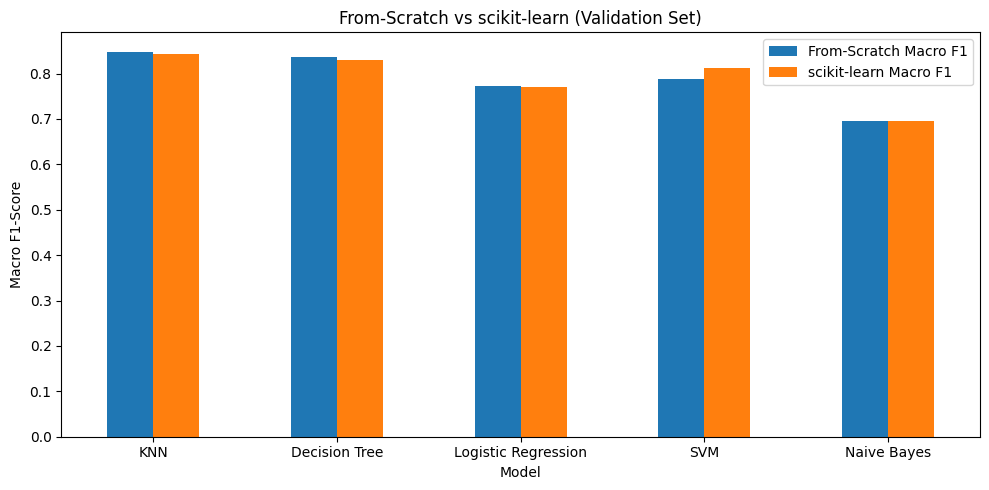

,Model,From-Scratch Macro F1,scikit-learn Macro F1,Difference
0,KNN,0.84835,0.84279,0.00556
1,Decision Tree,0.83564,0.82948,0.00616
2,Logistic Regression,0.77200,0.76930,0.00270
3,SVM,0.78797,0.81218,-0.02421
4,Naive Bayes,0.69620,0.69620,-0.00000


In [13]:
def compare_sklearn(
    X_tr_np: np.ndarray,
    y_tr: pd.Series,
    X_va_np: np.ndarray,
    y_va: pd.Series,
    scratch_df: pd.DataFrame,
    params: dict = ACTIVE_PARAMS,
) -> pd.DataFrame:
    """Bandingkan Macro F1 model from-scratch dengan scikit-learn pada split yang sama."""
    kp, dp, lp, sp, np_ = params['knn'], params['dtl'], params['lr'], params['svm'], params['nb']
    sk_models = {
        'KNN': KNeighborsClassifier(n_neighbors=kp['k_neighbors'], weights=kp['weights'], metric=kp['metric'], n_jobs=-1),
        'Decision Tree': DecisionTreeClassifier(
            criterion=dp['criterion'] if dp['criterion'] != 'gain_ratio' else 'entropy',
            max_depth=dp['max_depth'], min_samples_leaf=dp['min_samples_leaf'],
            min_samples_split=dp['min_samples_split'], ccp_alpha=dp['ccp_alpha'], random_state=CFG.SEED,
        ),
        'Logistic Regression': LogisticRegression(C=lp['C'], max_iter=lp['max_iter'], random_state=CFG.SEED),
        'SVM': SVC(C=sp['C'], kernel=sp['kernel'], random_state=CFG.SEED),
        'Naive Bayes': GaussianNB(var_smoothing=np_['var_smoothing']),
    }
    rows = []
    for name, clf in sk_models.items():
        clf.fit(X_tr_np, y_tr)
        sk_f1 = f1_score(y_va, clf.predict(X_va_np), average='macro')
        match = scratch_df.loc[scratch_df['Model'] == name, 'Macro F1']
        sm_f1 = float(match.iloc[0]) if len(match) else np.nan
        rows.append({
            'Model': name,
            'From-Scratch Macro F1': round(sm_f1, 5) if pd.notna(sm_f1) else np.nan,
            'scikit-learn Macro F1': round(sk_f1, 5),
            'Difference': round(sm_f1 - sk_f1, 5) if pd.notna(sm_f1) else np.nan,
        })
    comp_df = pd.DataFrame(rows)
    comp_df.set_index('Model')[['From-Scratch Macro F1', 'scikit-learn Macro F1']].plot(
        kind='bar', figsize=(10, 5), rot=0
    )
    plt.ylabel('Macro F1-Score')
    plt.title('From-Scratch vs scikit-learn (Validation Set)')
    plt.tight_layout()
    plt.show()
    return comp_df

comparison_df = compare_sklearn(
    X_train_prep.to_numpy(), y_train, X_val_prep.to_numpy(), y_val, scratch_results
)
display(comparison_df)

---

# 9. Saving and Loading Models <a name="9"></a>

---

In [16]:
def save_model(model_name: str, model, prep, model_dir: Path) -> tuple[Path, Path]:
    """Simpan model from-scratch (JSON bawaan) dan preprocessor ke disk."""
    slug = model_name.lower().replace(' ', '_')
    model_path = model.save(f'best_{slug}')
    prep_path = model_dir / 'preprocessor.pkl'
    with open(prep_path, 'wb') as f:
        pickle.dump(prep, f)
    print(f'Saved {model_name} -> {model_path}')
    return Path(model_path), prep_path

def load_model(model_cls, model_path: Path, prep_path: Path):
    """Muat kembali model from-scratch dan preprocessor dari disk."""
    model = model_cls.load(model_path)
    with open(prep_path, 'rb') as f:
        prep = pickle.load(f)
    print(f'Loaded {model_cls.__name__} <- {model_path}')
    return model, prep

saved_model_path, saved_prep_path = save_model(
    BEST_MODEL_NAME, scratch_models[BEST_MODEL_NAME], preprocessor, CFG.MODEL_DIR
)
# loaded_model, loaded_prep = load_model(
#     type(scratch_models[BEST_MODEL_NAME]), saved_model_path, saved_prep_path
# )

Saved KNN -> /datasets/output/saved_models/best_knn.json


---

# 10. Kaggle Submission <a name="10"></a>

---

In [17]:
def make_model(model_name: str, params: dict = ACTIVE_PARAMS):
    """Inisialisasi ulang model from-scratch terbaik untuk refit penuh."""
    if model_name == 'KNN':
        return sm_KNN(**params['knn'])
    if model_name == 'Decision Tree':
        return sm_DecisionTreeClassifier(**params['dtl'], random_state=CFG.SEED)
    if model_name == 'Logistic Regression':
        return sm_LogisticRegression(**params['lr'], random_state=CFG.SEED)
    if model_name == 'SVM':
        return sm_SVM(**params['svm'], random_state=CFG.SEED)
    return sm_NaiveBayes(**params['nb'])

def make_submission(
    model_name: str,
    X_full_df: pd.DataFrame,
    y_full_ser: pd.Series,
    X_test_df: pd.DataFrame,
    test_ids: pd.Series,
    out_path: Path,
) -> pd.DataFrame:
    """Fit preprocessor & model from-scratch terbaik pada full train.csv lalu prediksi test.csv."""
    prep = make_preprocessor(X_full_df)
    X_full_np = prep.fit_transform(X_full_df)
    X_test_np = prep.transform(X_test_df)

    model = make_model(model_name)
    if model_name == 'Naive Bayes':
        cols = list(prep.get_feature_names_out())
        model.fit(pd.DataFrame(X_full_np, columns=cols), y_full_ser.reset_index(drop=True))
        preds = model.predict(pd.DataFrame(X_test_np, columns=cols))
    else:
        model.fit(X_full_np, y_full_ser.to_numpy())
        preds = model.predict(X_test_np)

    sub = pd.DataFrame({
        CFG.ID_COLUMN: test_ids.astype(str).values,
        CFG.TARGET_COLUMN: np.asarray(preds, dtype=int),
    })
    assert len(sub) == len(test_ids), 'Jumlah baris submission tidak sesuai!'
    assert sub.isna().sum().sum() == 0, 'Submission mengandung NaN!'
    assert (sub[CFG.ID_COLUMN].values == test_ids.astype(str).values).all(), 'Urutan ID berubah!'

    sub.to_csv(out_path, index=False)
    print(f'Submission ({model_name}) saved -> {out_path} | Shape: {sub.shape}')
    print(sub[CFG.TARGET_COLUMN].value_counts(normalize=True).round(4))
    return sub

submission_df = make_submission(
    BEST_MODEL_NAME, X_full, y_full, X_test, test_df[CFG.ID_COLUMN], CFG.OUTPUT_DIR / 'submission.csv'
)
display(submission_df.head())

Submission (KNN) saved -> /datasets/_deepnote_work/output/submission.csv | Shape: (6844, 2)
is_canceled
0    0.7034
1    0.2966
Name: proportion, dtype: float64


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# 11. Error Analysis <a name="11"></a>

---

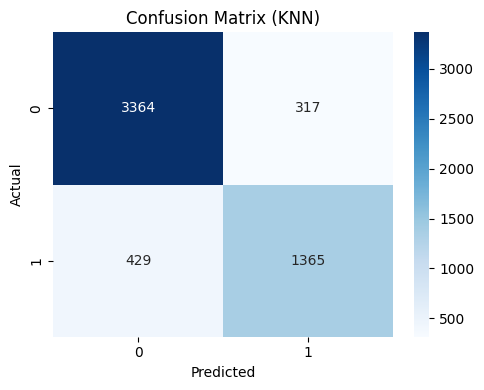

Validation Accuracy : 0.8637
Validation Macro F1 : 0.8428


,count,mean
booking_channel,,
Airline,16,0.1875
Complimentary,58,0.0345
Corporate,309,0.0777
Offline Agent,1573,0.0725
Online Travel Agent,3519,0.1714


In [18]:
def error_analysis(val_raw_df: pd.DataFrame, y_true: pd.Series, y_pred: np.ndarray, model_name: str) -> None:
    """Tampilkan confusion matrix dan breakdown error berdasarkan booking_channel."""
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(f'Confusion Matrix ({model_name})')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    plt.tight_layout()
    plt.show()

    df_err = val_raw_df.reset_index(drop=True).copy()
    df_err['actual'] = y_true.to_numpy()
    df_err['pred'] = np.asarray(y_pred, dtype=int)
    df_err['is_error'] = (df_err['actual'] != df_err['pred']).astype(int)

    print(f'Validation Accuracy : {accuracy_score(y_true, y_pred):.4f}')
    print(f'Validation Macro F1 : {f1_score(y_true, y_pred, average="macro"):.4f}')
    display(df_err.groupby('booking_channel', dropna=False)['is_error'].agg(['count', 'mean']).round(4))

best_val_pred = (
    scratch_preds[BEST_MODEL_NAME]
    if BEST_MODEL_NAME in scratch_preds
    else scratch_models[BEST_MODEL_NAME].predict(X_val_prep.to_numpy())
)
error_analysis(X_val_raw, y_val, best_val_pred, BEST_MODEL_NAME)

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=0d9f1050-26d5-458e-98a2-269a7d18b08a' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>